QUESTION NO. 1

In [6]:
import math
raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
    print("Converted value:", kc)
    print("Converted value type:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Invalid Kc: enter a finite number greater than 0.")
    else:
        a = kc
        b = -(2 * kc + 1)
        c = kc
        discriminant = b**2 - 4 * a * c

        print("a =", a)
        print("b =", b)
        print("c =", c)
        print("Discriminant =", discriminant)

        if discriminant >= 0:
            sqrt_discriminant = math.sqrt(discriminant)
            root_plus = (-b + sqrt_discriminant) / (2 * a)
            root_minus = (-b - sqrt_discriminant) / (2 * a)
            print("Root (+) =", root_plus)
            print("Root (-) =", root_minus)

            physical_roots = [root for root in (root_plus, root_minus) if 0 <= root <= 1]
            if physical_roots:
                physical_root = physical_roots[0]
                print("Physically meaningful root (0 <= x <= 1) =", physical_root)

                initial_A = 1.0
                initial_B = 1.0
                equilibrium_A = initial_A - physical_root
                equilibrium_B = initial_B - physical_root
                equilibrium_C = physical_root
                conversion = physical_root / initial_A * 100

                print(f"Equilibrium [A] = {equilibrium_A:.3f} mol/L")
                print(f"Equilibrium [B] = {equilibrium_B:.3f} mol/L")
                print(f"Equilibrium [C] = {equilibrium_C:.3f} mol/L")
                print(f"Limiting reactant conversion = {conversion:.3f}%")

                if conversion >= 70:
                    classification = "High"
                elif conversion >= 40:
                    classification = "Moderate"
                else:
                    classification = "Low"
                print("Conversion classification:", classification)
            else:
                print("No root lies in the physical range 0 <= x <= 1.")
        else:
            print("No real roots exist.")
except ValueError:
    print("Invalid input: Kc must be a number.")

Raw input type: <class 'str'>
Converted value: 4.0
Converted value type: <class 'float'>
a = 4.0
b = -9.0
c = 4.0
Discriminant = 17.0
Root (+) = 1.6403882032022077
Root (-) = 0.6096117967977924
Physically meaningful root (0 <= x <= 1) = 0.6096117967977924
Equilibrium [A] = 0.390 mol/L
Equilibrium [B] = 0.390 mol/L
Equilibrium [C] = 0.610 mol/L
Limiting reactant conversion = 60.961%
Conversion classification: Moderate


QUESTION NO. 2 

In [7]:
import math

C0 = 2.0
k = 0.08
delta_t = 1.0

print("Euler method: 10-minute simulation")
print(f"{'Time (min)':<12}{'Concentration (mol/L)':<26}{'Conversion (%)':>16}")
print("-" * 54)

concentration = C0
for time in range(11):
    if time > 0:
        concentration = concentration - k * concentration * delta_t
    conversion = (C0 - concentration) / C0 * 100
    print(f"{time:<12}{concentration:<26.6f}{conversion:>16.3f}")

euler_C_10 = concentration
exact_C_10 = C0 * math.exp(-k * 10)
absolute_error = abs(euler_C_10 - exact_C_10)

print(f"\nEuler concentration at 10 min: {euler_C_10:.6f} mol/L")
print(f"Exact concentration at 10 min: {exact_C_10:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

concentration = C0
time = 0
conversion = 0.0
while conversion < 60 and time < 100:
    concentration = concentration - k * concentration * delta_t
    time += 1
    conversion = (C0 - concentration) / C0 * 100

print("\nSimulation until 60% conversion or 100 min:")
print(f"Time needed: {time} min")
print(f"Final concentration: {concentration:.6f} mol/L")
print(f"Final conversion: {conversion:.3f}%")

Euler method: 10-minute simulation
Time (min)  Concentration (mol/L)       Conversion (%)
------------------------------------------------------
0           2.000000                             0.000
1           1.840000                             8.000
2           1.692800                            15.360
3           1.557376                            22.131
4           1.432786                            28.361
5           1.318163                            34.092
6           1.212710                            39.364
7           1.115693                            44.215
8           1.026438                            48.678
9           0.944323                            52.784
10          0.868777                            56.561

Euler concentration at 10 min: 0.868777 mol/L
Exact concentration at 10 min: 0.898658 mol/L
Absolute error: 0.029881 mol/L

Simulation until 60% conversion or 100 min:
Time needed: 11 min
Final concentration: 0.799275 mol/L
Final conversion: 60.036%

QUESTION NO. 3 

In [8]:
def factorial(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")
    if n <= 1:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or not isinstance(r, int) or n < 0 or r < 0 or r > n:
        raise ValueError("Invalid input: n and r must be non-negative integers with r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


try:
    print("Number of formulations for n=6, r=3:", combination(6, 3))
except ValueError as error:
    print(error)

try:
    print("Number of formulations for n=5, r=7:", combination(5, 7))
except ValueError as error:
    print(error)


def fib_iter(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")
    numbers = []
    current, next_number = 0, 1
    for _ in range(n):
        numbers.append(current)
        current, next_number = next_number, current + next_number
    return numbers


def fib_rec(k):
    if not isinstance(k, int) or k < 0:
        raise ValueError("k must be a non-negative integer.")
    if k <= 1:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
iterative_numbers = fib_iter(n)
recursive_numbers = [fib_rec(index) for index in range(n)]
print("First 10 Fibonacci numbers:", iterative_numbers)
print("Iterative and recursive results agree:", iterative_numbers == recursive_numbers)

print(f"\n{'Sample No.':<12}{'Fibonacci tag':<20}{'Sampling time (min)':>20}")
print("-" * 52)
for sample_number, (fibonacci_index, tag) in enumerate(zip(range(n), iterative_numbers), start=1):
    print(f"{sample_number:<12}{f'F_{fibonacci_index} = {tag}':<20}{tag * 2:>20}")

Number of formulations for n=6, r=3: 20
Invalid input: n and r must be non-negative integers with r <= n.
First 10 Fibonacci numbers: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]
Iterative and recursive results agree: True

Sample No.  Fibonacci tag        Sampling time (min)
----------------------------------------------------
1           F_0 = 0                                0
2           F_1 = 1                                2
3           F_2 = 1                                2
4           F_3 = 2                                4
5           F_4 = 3                                6
6           F_5 = 5                               10
7           F_6 = 8                               16
8           F_7 = 13                              26
9           F_8 = 21                              42
10          F_9 = 34                              68


QUESTION NO. 4 

CSV shape: (6, 3)
CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run 1 mean: 0.537 mol/L; standard deviation: 0.293 mol/L
Run 2 mean: 0.403 mol/L; standard deviation: 0.349 mol/L
Run 2 shows more variation.


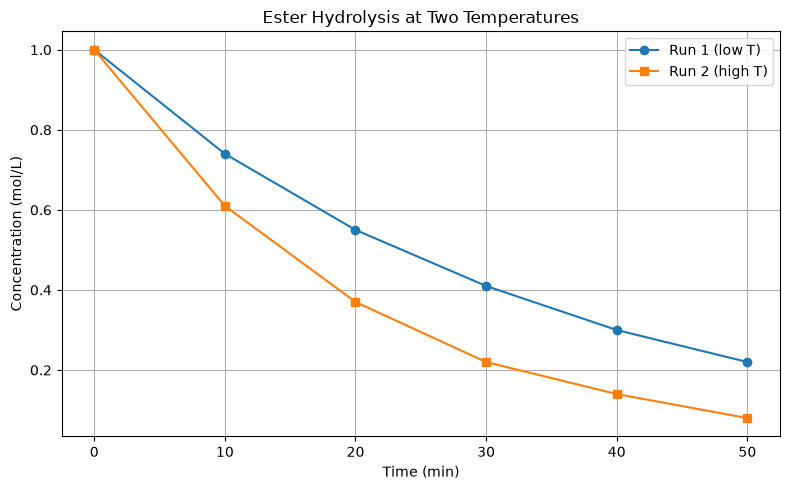


Mean P x V (k): 4.024 L*bar


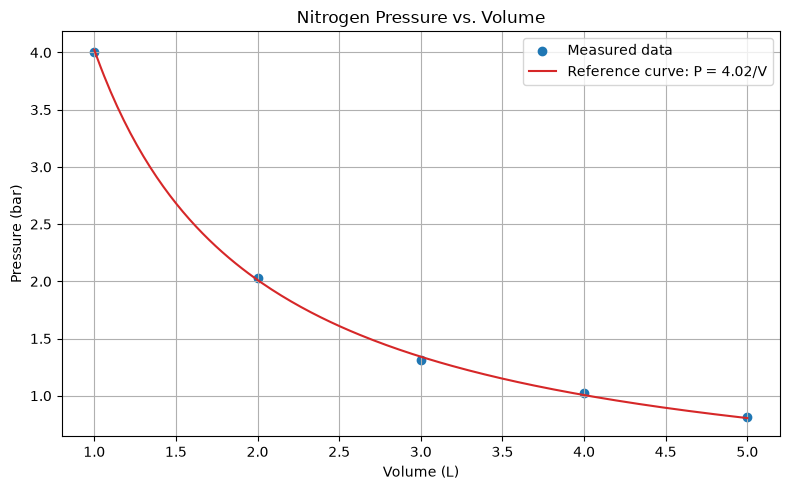

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_mol_L": [1.00, 0.61, 0.37, 0.22, 0.14, 0.08],
})

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics_from_csv["Run1_mol_L"].mean()
run1_std = kinetics_from_csv["Run1_mol_L"].std()
run2_mean = kinetics_from_csv["Run2_mol_L"].mean()
run2_std = kinetics_from_csv["Run2_mol_L"].std()

print(f"\nRun 1 mean: {run1_mean:.3f} mol/L; standard deviation: {run1_std:.3f} mol/L")
print(f"Run 2 mean: {run2_mean:.3f} mol/L; standard deviation: {run2_std:.3f} mol/L")
if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run1_mol_L"], marker="o", label="Run 1 (low T)")
ax.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run2_mol_L"], marker="s", label="Run 2 (high T)")
ax.set_title("Ester Hydrolysis at Two Temperatures")
ax.set_xlabel("Time (min)")
ax.set_ylabel("Concentration (mol/L)")
ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

gas_df = pd.DataFrame({
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [4.00, 2.03, 1.31, 1.02, 0.81],
})
gas_k = (gas_df["Volume_L"] * gas_df["Pressure_bar"]).mean()
print(f"\nMean P x V (k): {gas_k:.3f} L*bar")

curve_volume = np.linspace(gas_df["Volume_L"].min(), gas_df["Volume_L"].max(), 200)
curve_pressure = gas_k / curve_volume

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(gas_df["Volume_L"], gas_df["Pressure_bar"], label="Measured data")
ax.plot(curve_volume, curve_pressure, color="tab:red", label=f"Reference curve: P = {gas_k:.2f}/V")
ax.set_title("Nitrogen Pressure vs. Volume")
ax.set_xlabel("Volume (L)")
ax.set_ylabel("Pressure (bar)")
ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()